```{contents}
:local:
:depth: 2
```

# 2.2 Lagrange Multipliers and KKT Conditions

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 4, Lesson 4: *Constrained Optimization and Lagrange Function*
- Module 4, Lesson 5: *KKT Conditions for Optimality*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Form the Lagrange function of a constrained problem and derive its stationarity conditions.
- Explain a Lagrange multiplier three ways: as the ratio of two parallel gradients, as a constraint force, and as the sensitivity of the optimal objective to the constraint's right-hand side.
- Derive the equilibrium of a water electrolyzer as a constrained Gibbs minimization, identify its multipliers as elemental chemical potentials and the electron price $-FU$, and recover the Nernst equation.
- State the KKT conditions, classify inequality constraints as active or inactive, and apply complementary slackness.
- Solve the ohmic dispatch with a binding capacity from its KKT conditions and read the multipliers as the hydrogen price and a capacity rent.
:::

In Topic 2.1 we found the minimum of an unconstrained function, where the gradient vanishes and the Hessian is positive semidefinite. However, real problems have constraints, and at a constrained minimum the gradient of the objective usually does *not* vanish. In this topic we will build the conditions that replace "gradient equals zero" when there are constraints, and we will do this in two steps: first we look at equality constraints, which lead to Lagrange multipliers, and then we add inequality constraints, which lead to the Karush–Kuhn–Tucker (KKT) conditions. Along the way we will derive the equilibrium of the water electrolyzer that we solved numerically in Topic 1.2, and we will see that its multipliers are quantities that a chemist already knows.

## The Lagrange function

A general constrained NLP has $M$ equality and $N$ inequality constraints:

$$
\begin{aligned}
\min_x \quad & f(x) \\
\text{s.t.} \quad & h_j(x) = b_j, \quad j = 1, \ldots, M \\
& g_k(x) \le 0, \quad k = 1, \ldots, N .
\end{aligned}
$$

The simplest way to deal with an equality constraint is to get rid of it. If we can rearrange $h_j(x) = b_j$ to solve for one variable explicitly, then we can substitute it into the objective, which is called **variable elimination**. This is what we used in Topic 2.1 to remove the demand constraint from the dispatch, and many solvers also do it automatically. However, elimination fails if the constraint cannot be solved for a variable in closed form, and even when it works it hides the information we will most want, which is the value of the constraint.

The general alternative is to bring the constraints into the objective. For a problem with equality constraints only, the **Lagrange function** (or Lagrangian) is

$$
\mathcal{L}(x, \lambda) = f(x) - \sum_j \lambda_j \left(h_j(x) - b_j\right),
$$

with one new variable, a **Lagrange multiplier** $\lambda_j$, for each constraint. At any feasible point the added terms are zero, so $\mathcal{L} = f$ there, and the constrained optimum is a stationary point of $\mathcal{L}$ in both sets of variables:

$$
\nabla_x \mathcal{L} = \nabla f(x) - \sum_j \lambda_j \nabla h_j(x) = 0, \qquad \frac{\partial \mathcal{L}}{\partial \lambda_j} = -(h_j(x) - b_j) = 0 .
$$

The second set of equations simply returns the constraints, while the first set says that the gradient of the objective is a combination of the constraint gradients. Think of $\lambda$ as a parameter that we adjust until the unconstrained stationary point of $\mathcal{L}$ happens to satisfy the constraints, at which point it also solves the original problem.

A note on signs. Many texts, and the lectures, write the constraints as $h_j(x) = 0$ and the Lagrangian as $\mathcal{L} = f + \sum_j \lambda_j h_j$. That convention gives the same $x^*$ and multipliers of the opposite sign, so that the sensitivity of the optimum to a constraint's right-hand side is $-\lambda$. We use $f - \lambda(h - b)$ throughout this book, including Topics 2.1 and 2.3, because it makes $\lambda$ equal to $+\partial f^*/\partial b$, the sensitivity we derive below, which is also the sign Pyomo reports for a minimization. When comparing with the lectures, flip the sign of every multiplier.

### Three readings of a multiplier

**Geometry: tangency.** Let's take two stacks, A and B, that share a demand of $D = 1$, so that the feasible set $x_A + x_B = 1$ is a line in the plane of loads. As we walk along this line we cross the contours of the total power, $f = P_A + P_B$, and $f$ keeps decreasing as long as the line cuts the contours at an angle, so we stop at the point where the line is *tangent* to a contour. At this point the gradient of $f$ is perpendicular to the line, which means that it is parallel to the normal of the constraint, $\nabla h = (1, 1)$, and the multiplier is just the ratio of their lengths: $\nabla f = \lambda \nabla h$.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


two stacks, D = 1: x = (0.4118, 0.5882), grad f = [1.4118 1.4118], lambda = 1.4118 (grad f = lambda * (1, 1))


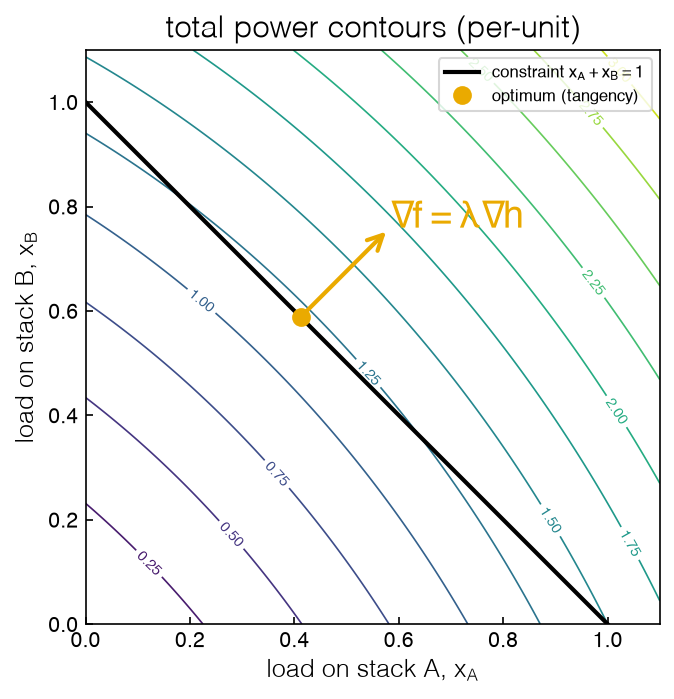

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from scipy.optimize import linprog
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part2a_tools as t2

rA, rB = el.R_OHMIC['A'], el.R_OHMIC['B']
D2 = 1.0
lam2 = 1 + D2 / (1 / (2 * rA) + 1 / (2 * rB))           # equal marginal power
xA, xB = (lam2 - 1) / (2 * rA), (lam2 - 1) / (2 * rB)
grad_f = np.array([1 + 2 * rA * xA, 1 + 2 * rB * xB])
print(f"two stacks, D = 1: x = ({xA:.4f}, {xB:.4f}), grad f = {np.round(grad_f, 4)}, "
      f"lambda = {lam2:.4f} (grad f = lambda * (1, 1))")

g = np.linspace(0, 1.1, 200)
XA, XB = np.meshgrid(g, g)
fig, ax = plt.subplots(figsize=(5.2, 5))
cs = ax.contour(XA, XB, el.p_ohmic(XA, 'A') + el.p_ohmic(XB, 'B'), levels=12, linewidths=0.8)
ax.clabel(cs, fontsize=7)
ax.plot(g, D2 - g, 'k', lw=2, label='constraint $x_A + x_B = 1$')
ax.plot(xA, xB, 'o', color='C1', ms=8, label='optimum (tangency)')
ax.annotate('', xy=(xA + 0.12 * grad_f[0], xB + 0.12 * grad_f[1]), xytext=(xA, xB),
            arrowprops=dict(arrowstyle='->', lw=2, color='C1'))
ax.text(xA + 0.17, xB + 0.17, r'$\nabla f = \lambda \nabla h$', color='C1')
ax.set_xlim(0, 1.1); ax.set_ylim(0, 1.1); ax.set_aspect('equal')
ax.set_xlabel('load on stack A, $x_A$'); ax.set_ylabel('load on stack B, $x_B$')
ax.set_title('total power contours (per-unit)'); ax.legend(loc='upper right', fontsize=8);

Both components of $\nabla f$ are equal to 1.4118, so the arrow points along $(1, 1)$ (i.e. perpendicular to the constraint line), and $\lambda = 1.4118$.

The code found this point by following the same recipe that the lectures use for a Lagrange problem:

1. **Fix $\lambda$ and minimize $\mathcal{L}$ over $x$.** Here $\partial \mathcal{L}/\partial x_i = 1 + 2 r_i x_i - \lambda = 0$ gives $x_i(\lambda) = (\lambda - 1)/(2r_i)$.
2. **Check that this is a minimum.** The Hessian of $\mathcal{L}$ in $x$ is $\mathrm{diag}(2r_A, 2r_B)$, positive definite, so $x(\lambda)$ is the global minimizer of $\mathcal{L}$ for that $\lambda$.
3. **Choose $\lambda$ so the constraint holds.** Substituting into $x_A + x_B = D$ gives $\lambda = 1 + D/\big(1/(2r_A) + 1/(2r_B)\big)$. For that $\lambda$, the unconstrained minimizer of $\mathcal{L}$ is feasible, the penalty term vanishes, and the point solves the constrained problem.

**Mechanics: a bead on a wire.** Lagrange's own picture was mechanical. If we thread a bead on a curved wire, it comes to rest where gravity (which is minus the gradient of the potential energy) is exactly cancelled by the force that the wire exerts on the bead, and the wire can only push perpendicular to itself. This force balance, $\nabla f = \lambda \nabla h$, is the Lagrange condition, and the multiplier is the magnitude of the constraint force, so if we think of a constraint as a wall, then its multiplier tells us how hard the wall has to push.

**Sensitivity: the envelope theorem.** The most useful reading is a quantitative one, and it comes from asking how the optimal objective $f^*(b)$ changes as we move the right-hand side of the constraint, which gives

$$
\lambda_j = \frac{\partial f^*}{\partial b_j} .
$$

The argument is short: at the optimum $f^*(b) = \mathcal{L}(x^*(b), \lambda^*(b), b)$, and when we differentiate with respect to $b$ the terms that come from the change in $x^*$ and $\lambda^*$ vanish because $\mathcal{L}$ is already stationary in both, so only the explicit dependence of $\mathcal{L}$ on $b$ survives and that derivative is $\lambda$. This result is known as the **envelope theorem**, and it says that re-optimizing the internal variables contributes nothing to first order, so that a multiplier is the marginal value of relaxing its constraint.

For the three-stack ohmic dispatch this means that the multiplier on the demand constraint should be the extra power that is needed per extra unit of demand, which we can check with finite differences:

In [2]:
D, h = 1.2, 1e-5
lam, x, cost, _ = t2.ohmic_dispatch(D)
fd = (t2.ohmic_dispatch(D + h)[2] - t2.ohmic_dispatch(D - h)[2]) / (2 * h)
print(f"D = {D}: lambda = {lam:.5f}, dC*/dD by finite difference = {fd:.5f}")

D = 1.2: lambda = 1.38182, dC*/dD by finite difference = 1.38182


:::{exercise}
:label: ex-t22-tangency

In the two-stack picture, change the demand to $D = 0.5$ and $D = 1.5$ and redraw. Does the tangency point move along a straight line in the $(x_A, x_B)$ plane? Derive the answer from $1 + 2r_A x_A = 1 + 2 r_B x_B$, then confirm it in the plot.
:::

## The electrolysis equilibrium, derived

In Topic 1.2 we solved the closed electrolysis cell numerically, and now we can derive its equilibrium with Lagrange multipliers, which will show us where the Nernst equation comes from and what the multipliers actually mean.

**The system.** We consider a cell at $T = 298.15$ K that holds liquid water and a closed 1 L headspace, where the hydrogen and oxygen collect as ideal gases. A power supply pushes $q$ moles of electrons through the cell at an applied voltage $U$ and does work $FUq$ on the system, where $F$ is the Faraday constant, and since the water is in large excess (1000 mol) it never runs out.

**The variables.** The variables in this problem are the amounts $n_{\mathrm{H_2O}}$, $n_{\mathrm{H_2}}$ and $n_{\mathrm{O_2}}$, along with the charge $q$.

**The objective.** At fixed temperature the system minimizes its free energy less the work that is done on it, $G(n) - FUq$. Since liquid water is a pure condensed phase, its chemical potential is fixed at the standard value $\mu^0_{\mathrm{H_2O}} = -\Delta G^0 = -237.13$ kJ/mol, while each gas contributes $n_i\left[\mu^0_i + RT\left(\ln(p_i/p^0) - 1\right)\right]$ with $\mu^0_i = 0$ and partial pressure $p_i = n_i RT/V$, so that the derivative of this term is just the chemical potential of the gas, $\mu_i = \mu_i^0 + RT \ln(p_i/p^0)$.

**The constraints.** We need to conserve hydrogen atoms, oxygen atoms and charge, and Faraday's law tells us that each molecule of H₂ needs two electrons from the supply:

$$
\begin{aligned}
\text{H:} \quad & 2 n_{\mathrm{H_2O}} + 2 n_{\mathrm{H_2}} = b_{\mathrm{H}} & (\lambda_{\mathrm{H}}) \\
\text{O:} \quad & n_{\mathrm{H_2O}} + 2 n_{\mathrm{O_2}} = b_{\mathrm{O}} & (\lambda_{\mathrm{O}}) \\
\text{charge:} \quad & q - 2 n_{\mathrm{H_2}} = 0 & (\lambda_e)
\end{aligned}
$$

**The Lagrangian.**

$$
\mathcal{L} = G(n) - FUq - \lambda_{\mathrm{H}}\left(2 n_{\mathrm{H_2O}} + 2 n_{\mathrm{H_2}} - b_{\mathrm{H}}\right) - \lambda_{\mathrm{O}}\left(n_{\mathrm{H_2O}} + 2 n_{\mathrm{O_2}} - b_{\mathrm{O}}\right) - \lambda_e \left(q - 2 n_{\mathrm{H_2}}\right).
$$

**Stationarity.** If we set each partial derivative to zero we get one equation per variable:

$$
\begin{aligned}
\partial / \partial q: \quad & -FU - \lambda_e = 0 & \Rightarrow \quad & \lambda_e = -FU \\
\partial / \partial n_{\mathrm{H_2}}: \quad & \mu_{\mathrm{H_2}} - 2\lambda_{\mathrm{H}} + 2 \lambda_e = 0 & \Rightarrow \quad & \mu_{\mathrm{H_2}} = 2\lambda_{\mathrm{H}} + 2FU \\
\partial / \partial n_{\mathrm{O_2}}: \quad & \mu_{\mathrm{O_2}} - 2\lambda_{\mathrm{O}} = 0 & \Rightarrow \quad & \mu_{\mathrm{O_2}} = 2\lambda_{\mathrm{O}} \\
\partial / \partial n_{\mathrm{H_2O}}: \quad & \mu_{\mathrm{H_2O}} - 2\lambda_{\mathrm{H}} - \lambda_{\mathrm{O}} = 0 & \Rightarrow \quad & \mu_{\mathrm{H_2O}} = 2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}}
\end{aligned}
$$

This tells us that the chemical potential of every species is the sum of the multipliers of the things it is made of, counted by the constraint coefficients. The electrons are booked on H₂, since the charge constraint links $q$ to $n_{\mathrm{H_2}}$.

**Nernst falls out.** Now we can eliminate the multipliers to get $\mu_{\mathrm{H_2}} + \tfrac{1}{2}\mu_{\mathrm{O_2}} - \mu_{\mathrm{H_2O}} = 2FU$. If we substitute the chemical potentials, we get

$$
\Delta G^0 + RT \ln\left(\frac{p_{\mathrm{H_2}}}{p^0}\left(\frac{p_{\mathrm{O_2}}}{p^0}\right)^{1/2}\right) = 2FU
\quad \Longleftrightarrow \quad
\frac{p_{\mathrm{H_2}}}{p^0}\left(\frac{p_{\mathrm{O_2}}}{p^0}\right)^{1/2} = \exp\left(\frac{2F(U - E^0)}{RT}\right),
$$

where $E^0 = \Delta G^0 / 2F = 1.229$ V. This is the Nernst equation for water electrolysis! We never put it into the model, but it follows directly from the stationarity conditions of the Lagrangian.

Now let's solve the model in Pyomo with Ipopt, read the three multipliers from the solver, and check them against the derivation:

In [3]:
F, R, T, P0, V = t2.F, t2.R, t2.T, t2.P0, t2.V_HEAD
DG0, E0, NW = t2.DG0, t2.E0, t2.N_WATER

def kernel(U, bH=2 * NW, bO=NW):
    m = pyo.ConcreteModel()
    m.nw = pyo.Var(bounds=(1e-12, None), initialize=NW)       # liquid water
    m.nh = pyo.Var(bounds=(1e-14, None), initialize=1e-2)     # H2 in the headspace
    m.no = pyo.Var(bounds=(1e-14, None), initialize=5e-4)     # O2 in the headspace
    m.q = pyo.Var(bounds=(0, None), initialize=2e-3)          # mol of electrons passed
    gas = lambda n: n * (pyo.log(n * R * T / (V * P0)) - 1) * R * T
    m.obj = pyo.Objective(expr=-DG0 * m.nw + gas(m.nh) + gas(m.no) - F * U * m.q)
    m.H = pyo.Constraint(expr=2 * m.nw + 2 * m.nh == bH)
    m.O = pyo.Constraint(expr=m.nw + 2 * m.no == bO)
    m.e = pyo.Constraint(expr=m.q - 2 * m.nh == 0)
    m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    ipopt.solve(m, options={'tol': 1e-12, 'acceptable_tol': 1e-12})
    return m

ipopt = t2.get_solver('ipopt')
dUs = np.array([-0.15, -0.10, -0.05, 0.0, 0.05, 0.10, 0.15])
rows = []
print(" U-E0 (V) | p_H2 (bar) | p_H2*sqrt(p_O2) | Nernst    | lam_H   lam_O   lam_e   -FU  (kJ/mol)")
for dU in dUs:
    U = E0 + dU
    if ipopt is not None:
        m = kernel(U)
        nh, no = pyo.value(m.nh), pyo.value(m.no)
        lH, lO, le = (m.dual[c] for c in (m.H, m.O, m.e))
    else:                                    # fallback: the closed form derived above
        nh, no, lH, lO = t2.kernel_closed_form(U); le = -F * U
    pH, pO = nh * R * T / V / P0, no * R * T / V / P0
    rows.append((dU, pH, lH, lO, le))
    print(f"  {dU:+.2f}   | {pH:10.4g} | {pH * pO**0.5:15.4g} | {np.exp(2*F*dU/(R*T)):9.4g} | "
          f"{lH/1e3:7.2f} {lO/1e3:6.2f} {le/1e3:8.3f} {-F*U/1e3:8.3f}")
rows = np.array(rows)

 U-E0 (V) | p_H2 (bar) | p_H2*sqrt(p_O2) | Nernst    | lam_H   lam_O   lam_e   -FU  (kJ/mol)


  -0.15   |  0.0005244 |       8.491e-06 | 8.491e-06 | -113.45 -10.22 -104.092 -104.092


  -0.10   |   0.007023 |       0.0004162 | 0.0004162 | -115.06  -7.01 -108.916 -108.916


  -0.05   |    0.09407 |          0.0204 |    0.0204 | -116.67  -3.79 -113.741 -113.741


  +0.00   |       1.26 |               1 |         1 | -118.28  -0.57 -118.565 -118.565


  +0.05   |      16.87 |           49.02 |     49.02 | -119.89   2.64 -123.389 -123.389


  +0.10   |        226 |            2403 |      2403 | -121.49   5.86 -128.214 -128.214


  +0.15   |       3027 |       1.178e+05 | 1.178e+05 | -123.10   9.08 -133.038 -133.038


We can see that the equilibrium satisfies Nernst at every voltage, and the charge multiplier from the solver equals $-FU$ to the printed precision. Below $E^0$ there is only a trace of gas in the headspace. At $E^0$ there is 1.26 bar of hydrogen, and 0.10 V above $E^0$ there is 226 bar. (A real gas is far from ideal above about 100 bar, so the last rows are an idealization.)

We can do two more checks to confirm the sign convention and the identities. If $\lambda = \partial G^*/\partial b$, then adding a little hydrogen or oxygen to the cell should change the optimal free energy at the rates $\lambda_{\mathrm{H}}$ and $\lambda_{\mathrm{O}}$. We can also check that the chemical potentials we compute from the solution satisfy the three identities:

dG*/db_H = -119.887 kJ/mol (finite difference) vs lam_H = -119.887
dG*/db_O = 2.643 kJ/mol (finite difference) vs lam_O = 2.643
identity residuals (J/mol): mu_H2 - (2 lam_H + 2FU) = 8.9e-10, mu_O2 - 2 lam_O = 8.7e-10, mu_H2O - (2 lam_H + lam_O) = 2.9e-11


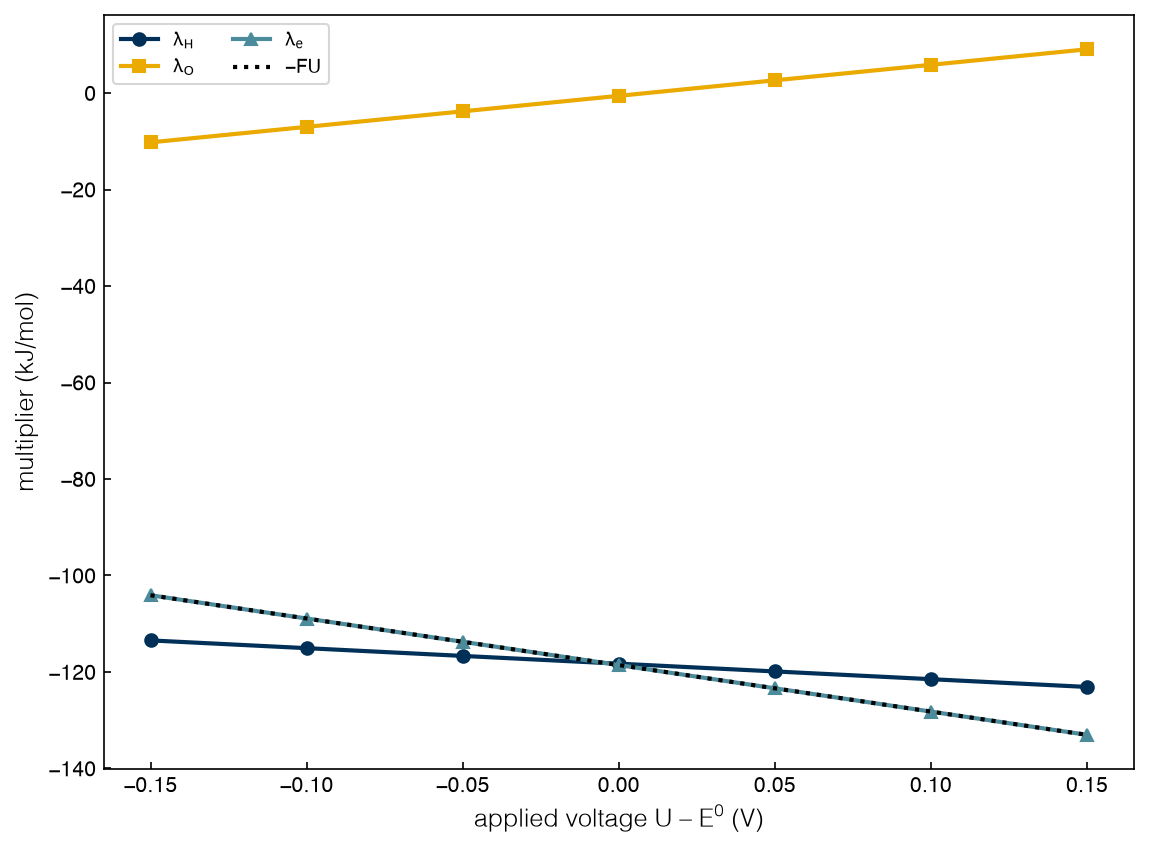

In [4]:
U = E0 + 0.05
if ipopt is not None:
    m = kernel(U); h = 1e-6
    G = lambda bH, bO: pyo.value(kernel(U, bH, bO).obj)
    fdH = (G(2*NW + h, NW) - G(2*NW - h, NW)) / (2 * h)
    fdO = (G(2*NW, NW + h) - G(2*NW, NW - h)) / (2 * h)
    lH, lO = m.dual[m.H], m.dual[m.O]
    print(f"dG*/db_H = {fdH/1e3:.3f} kJ/mol (finite difference) vs lam_H = {lH/1e3:.3f}")
    print(f"dG*/db_O = {fdO/1e3:.3f} kJ/mol (finite difference) vs lam_O = {lO/1e3:.3f}")
    mu = lambda n: R * T * np.log(pyo.value(n) * R * T / (V * P0))
    print(f"identity residuals (J/mol): mu_H2 - (2 lam_H + 2FU) = {mu(m.nh) - (2*lH + 2*F*U):.1e}, "
          f"mu_O2 - 2 lam_O = {mu(m.no) - 2*lO:.1e}, mu_H2O - (2 lam_H + lam_O) = {-DG0 - (2*lH + lO):.1e}")
else:
    print("Ipopt not available: the finite-difference check needs a solver.")

fig, ax = plt.subplots()
ax.plot(rows[:, 0], rows[:, 2] / 1e3, 'o-', label=r'$\lambda_\mathrm{H}$')
ax.plot(rows[:, 0], rows[:, 3] / 1e3, 's-', label=r'$\lambda_\mathrm{O}$')
ax.plot(rows[:, 0], rows[:, 4] / 1e3, '^-', label=r'$\lambda_e$')
ax.plot(rows[:, 0], -F * (E0 + rows[:, 0]) / 1e3, 'k:', label=r'$-FU$')
ax.set_xlabel('applied voltage $U - E^0$ (V)')
ax.set_ylabel('multiplier (kJ/mol)')
ax.legend(ncol=2, fontsize=9);

The finite differences match the multipliers ($-119.887$ and $2.643$ kJ/mol at $U = E^0 + 0.05$ V), and the three identities hold to about $10^{-9}$ J/mol. As the voltage goes up, $\lambda_e$ falls along $-FU$ and $\lambda_{\mathrm{O}}$ rises as oxygen builds up. Meanwhile $\lambda_{\mathrm{H}}$ falls by half as much, which keeps $2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}}$ pinned at the chemical potential of liquid water.

**The thermodynamic reading.** The multipliers $\lambda_{\mathrm{H}}$ and $\lambda_{\mathrm{O}}$ are the **elemental chemical potentials**, that is, the change in the cell's free energy when one mole of H or O atoms is added and the system re-equilibrates, and stationarity says that each species present is in equilibrium with its elements. The charge multiplier $\lambda_e = -FU$ is the electrochemical potential of the electrons in the power supply, which acts as a reservoir of electrons at a fixed potential set by $U$. The Nernst equation then states that a mole of H₂ plus half a mole of O₂ has exactly the free energy of a mole of water plus the work of two moles of electrons.

**The economic reading.** The same equations also describe a market. The multipliers $\lambda_{\mathrm{H}}$ and $\lambda_{\mathrm{O}}$ are the prices of a raw H atom and a raw O atom, and stationarity is a no-arbitrage rule: every molecule sells for the price of its parts, or someone could profit by assembling or dismantling it. The power supply sells electrons at a posted price, and $FU$ is that price. With rough market prices of \$5/kg for hydrogen[^h2price], \$0.15/kg for oxygen[^o2price] and nearly nothing for water, the identities imply atom prices of about \$0.0024 per mole of O and $-$\$0.0012 per mole of H, and a break-even electron price of \$0.0062 per mole, which at the reversible voltage is \$0.19 per kWh. Electricity at \$0.05/kWh[^elecprice] costs about \$0.0017 per mole of electrons there, so ideal electrolysis would be about 3.8 times in the money. These prices are round illustrative numbers chosen to have the right order of magnitude, not market data.

[^h2price]: The U.S. Department of Energy put the cost of hydrogen from renewable electricity at about \$5/kg when it launched its Hydrogen Shot goal of \$1/kg: DOE, *Hydrogen Shot* fact sheet (August 2021), https://www.energy.gov/sites/default/files/2021-08/factsheet-hydrogen-shot-introduction-august2021.pdf.

[^o2price]: Merchant liquid oxygen delivered in bulk sells for a few tenths of a dollar per kilogram; for example, a 2025–26 municipal contract with Air Products prices it at \$208.98 per delivered ton (Westchester County, NY, contract 5857 BPS). Oxygen piped from an on-site plant is cheaper.

[^elecprice]: The average U.S. price of electricity to industrial customers was 8.51 cents/kWh in 2025 (U.S. EIA, *Electric Power Monthly*, Table 5.3, https://www.eia.gov/electricity/monthly/epm_table_grapher.php?t=epmt_5_3). Large electrolysis projects aim for cheaper power contracts, so \$0.05/kWh is a low but realistic figure for a dedicated plant.

:::{exercise}
:label: ex-t22-headspace

Double the headspace volume to 2 L (pass a different `V` by editing the model) and re-solve at $U = E^0$ and $U = E^0 + 0.05$ V. Which of $p_{\mathrm{H_2}}$, $\lambda_{\mathrm{H}}$, $\lambda_{\mathrm{O}}$ and $\lambda_e$ change, and which do not? Explain each answer from the stationarity equations.
:::

## The KKT conditions

Inequality constraints add a complication. At the optimum, each inequality is either **active** (i.e. it holds with equality, $g_k(x^*) = 0$) or **inactive** ($g_k(x^*) < 0$). An inactive constraint does not affect the solution at all, so we could delete it and nothing would change. An active constraint, on the other hand, behaves locally like an equality. The problem is that we do not know ahead of time which constraints will be active. The **Karush–Kuhn–Tucker (KKT) conditions** are the Lagrange conditions plus a set of logical switches that sort this out.

First, we add a multiplier $\nu_k$ for each inequality and write the Lagrangian as $\mathcal{L} = f(x) - \sum_j \lambda_j (h_j(x) - b_j) + \sum_k \nu_k g_k(x)$. A point $x^*$ is a KKT point if there are multipliers $\lambda$ and $\nu$ such that

| Condition | Statement | Meaning |
|---|---|---|
| Stationarity | $\nabla f(x^*) - \sum_j \lambda_j \nabla h_j(x^*) + \sum_k \nu_k \nabla g_k(x^*) = 0$ | the objective's pull is balanced by the constraints pushing back |
| Primal feasibility | $h_j(x^*) = b_j$, $g_k(x^*) \le 0$ | the point is allowed |
| Dual feasibility | $\nu_k \ge 0$ | a one-sided wall can only push, not pull |
| Complementary slackness | $\nu_k \, g_k(x^*) = 0$ | each inequality is active or its multiplier is zero |

Note that equality multipliers can have either sign, since an equality can push from either side, but inequality multipliers must be nonnegative. If a solver returned a negative $\nu_k$, then stepping off that constraint into the feasible region would lower the objective, so the constraint was not really holding the solution in place. Complementary slackness ties these two conditions together. A constraint that is not touching the solution exerts no force, and a constraint that exerts a force must be touching it.

The variables $x$ are called the **primal** variables and the multipliers are called the **dual** variables. Primal feasibility and dual feasibility are just the conditions on each set. In Topic 2.3 we will see that the multipliers solve an optimization problem of their own, which is called the dual problem.

**When are the KKT conditions enough?** If a problem satisfies a mild regularity condition (called a *constraint qualification*), then the KKT conditions are necessary for a local minimum. If the problem is convex (convex objective, convex inequalities, linear equalities) and also has a strictly feasible point (Slater's condition), then they are also sufficient, and any KKT point is a global minimum. However, for a non-convex problem a KKT point can be a local minimum, a saddle, or even a maximum.

### The hidden inequality in the electrolyzer

The electrolysis model has inequalities that we did not write as constraints, since the amounts cannot be negative: $n_i \ge 0$ and $q \ge 0$. If we add multipliers $\nu_i \ge 0$ on these bounds, stationarity in $n_{\mathrm{H_2}}$ becomes

$$
\mu_{\mathrm{H_2}} - (2\lambda_{\mathrm{H}} + 2FU) - \nu_{\mathrm{H_2}} = 0, \qquad n_{\mathrm{H_2}} \ge 0, \quad \nu_{\mathrm{H_2}} \ge 0, \quad \nu_{\mathrm{H_2}}\, n_{\mathrm{H_2}} = 0 .
$$

There are two cases:

- **Species present** ($n_{\mathrm{H_2}} > 0$): complementary slackness forces $\nu_{\mathrm{H_2}} = 0$, and we recover the Lagrange identity.
- **Species absent** ($n_{\mathrm{H_2}} = 0$): $\nu_{\mathrm{H_2}} \ge 0$, so $\mu_{\mathrm{H_2}}$ is *at or above* the price of its parts. Making it would cost more than it is worth. The species is **priced out**, and $\nu$ measures by how much.

In the closed cell the second case never happens, because the chemical potential of an ideal gas falls to $-\infty$ as its amount goes to zero, so some hydrogen always forms and every bound is inactive (which is why plain Lagrange multipliers were enough above). The absent case shows up when the chemical potential of a species does not depend on its amount. One example is a pure condensed phase, which appears or disappears as a whole, and the other is the **LP limit** from Topic 1.2, where the gases are drawn off continuously at 1 bar so that each mole of gas has the fixed chemical potential $\mu^0$. That model has only one degree of freedom, the extent $\xi$ (moles of H₂ made per mole of water), with objective $(\Delta G^0 - 2FU)\,\xi$ and bounds $0 \le \xi \le 1$, and we can get the bound multipliers directly from the LP solver:

In [5]:
for dU in (-0.05, +0.05):
    U = E0 + dU
    res = linprog([DG0 - 2 * F * U], bounds=[(0, 1)], method='highs')
    print(f"U = E0 {dU:+.2f} V: xi = {res.x[0]:.0f}; multiplier on xi >= 0: {res.lower.marginals[0]/1e3:+.3f} kJ/mol, "
          f"on xi <= 1: {res.upper.marginals[0]/1e3:+.3f} kJ/mol")
print(f"2F(E0 - U) at U = E0 - 0.05 V: {2 * F * 0.05 / 1e3:.3f} kJ/mol")

U = E0 -0.05 V: xi = 0; multiplier on xi >= 0: +9.649 kJ/mol, on xi <= 1: +0.000 kJ/mol
U = E0 +0.05 V: xi = 1; multiplier on xi >= 0: +0.000 kJ/mol, on xi <= 1: -9.649 kJ/mol
2F(E0 - U) at U = E0 - 0.05 V: 9.649 kJ/mol


Below the reversible voltage no hydrogen is made, and the lower bound carries a multiplier of 9.649 kJ/mol, which is exactly $2F(E^0 - U)$, so hydrogen is priced out by the shortfall in the electrons' work. Above the reversible voltage all the water is split and the upper bound is active instead, with a multiplier of $-9.649$ kJ/mol (scipy reports the multiplier of an upper bound as a nonpositive sensitivity $\partial f^*/\partial(\text{bound})$). In each case exactly one bound is active and the other carries a zero multiplier, as complementary slackness requires.

:::{exercise}
:label: ex-t22-priced-out

Use the LP above to sweep $U$ from $E^0 - 0.1$ to $E^0 + 0.1$ V and plot both bound multipliers against $U$. What happens at exactly $U = E^0$? Relate what you see to the flat objective of Topic 1.2.
:::

## KKT for the ohmic dispatch

Now apply KKT to the ohmic dispatch of Topic 2.1, keeping the capacity bounds:

$$
\min_x \sum_i \left(x_i + r_i x_i^2\right) \quad \text{s.t.} \quad \sum_i x_i = D \;\; (\lambda), \qquad x_i \le 1 \;\; (\mu_i \ge 0), \qquad -x_i \le 0 \;\; (\nu_i \ge 0).
$$

Stationarity for stack $i$ reads

$$
1 + 2 r_i x_i = \lambda - \mu_i + \nu_i .
$$

For a stack that is running but not full, both bounds are inactive, $\mu_i = \nu_i = 0$, and its **marginal power** $1 + 2 r_i x_i$ equals $\lambda$. This is the condition we found by elimination in Topic 2.1, now with $\lambda$ identified as the demand multiplier. For a full stack, $\mu_i = \lambda - (1 + 2r_i) \ge 0$, meaning that the price exceeds its marginal power at full load. For an idle stack, $\nu_i = 1 - \lambda \ge 0$, which cannot happen here because every stack's marginal power at zero load is 1 and the price is above 1. Because the problem is convex, the KKT point is the global minimum, and since the objective is strictly convex it is also unique.

When all of the bounds are inactive the solution has the closed form from Topic 2.1, $\lambda - 1 = D/\sum_i (1/2r_i)$, and when a bound binds we can fix that stack at capacity and apply the same formula to the other stacks. The helper `t2.ohmic_dispatch` does this by bisection on $\lambda$, and we can compare it with Ipopt if we write the capacity bounds as explicit constraints so that the solver reports their multipliers:

In [6]:
def dispatch_kkt(D):
    lam, x, cost, mu = t2.ohmic_dispatch(D)                    # exact, from the KKT conditions
    line = f"D = {D}: lambda = {lam:.5f}, x = {np.round(x, 4)}, cost {cost:.5f}, capacity multipliers {np.round(mu, 4)}"
    if ipopt is not None:
        m = pyo.ConcreteModel()
        m.S = pyo.Set(initialize=el.NAMES)
        m.x = pyo.Var(m.S, bounds=(0, None), initialize=D / 3)
        m.obj = pyo.Objective(expr=sum(m.x[i] + el.R_OHMIC[i] * m.x[i]**2 for i in m.S))
        m.demand = pyo.Constraint(expr=sum(m.x[i] for i in m.S) == D)
        m.cap = pyo.Constraint(m.S, rule=lambda m, i: m.x[i] <= 1)
        m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
        ipopt.solve(m, options={'tol': 1e-10})
        mu_ip = [-m.dual[m.cap[i]] for i in el.NAMES]          # Pyomo reports dC*/d(capacity) <= 0
        line += f"\n         Ipopt: lambda = {m.dual[m.demand]:.5f}, capacity multipliers {np.round(mu_ip, 4)}"
    print(line)
    return lam, x

lam12, x12 = dispatch_kkt(1.2)
lam25, x25 = dispatch_kkt(2.5)
print(f"marginal powers at D = 2.5: {np.round(1 + 2 * np.array(list(el.R_OHMIC.values())) * x25, 4)}")
for lam in (lam12, lam25):
    print(f"price {lam:.5f} per-unit = {lam * DG0 / 1e3:.0f} kJ/mol H2 = {lam * E0:.2f} V-equivalent "
          f"= {lam * DG0 / 2.01588 / 3600:.1f} kWh/kg")

D = 1.2: lambda = 1.38182, x = [0.3818 0.5455 0.2727], cost 1.42909, capacity multipliers [0. 0. 0.]
         Ipopt: lambda = 1.38182, capacity multipliers [0. 0. 0.]


D = 2.5: lambda = 1.87500, x = [0.875 1.    0.625], cost 3.50625, capacity multipliers [0.    0.175 0.   ]
         Ipopt: lambda = 1.87500, capacity multipliers [0.    0.175 0.   ]
marginal powers at D = 2.5: [1.875 1.7   1.875]
price 1.38182 per-unit = 328 kJ/mol H2 = 1.70 V-equivalent = 45.2 kWh/kg
price 1.87500 per-unit = 445 kJ/mol H2 = 2.30 V-equivalent = 61.3 kWh/kg


At $D = 1.2$ every stack is interior, which means that the marginal powers are all equal to $\lambda = 1.38182$ and the capacity multipliers are zero. At $D = 2.5$ (500 kg/h) stack B, which is the most efficient, reaches full load, so its bound becomes active and the price rises to $\lambda = 1.875$. Stacks A and C run at 0.875 and 0.625, where their marginal powers are equal to the price, while the marginal power of B at full load is only 1.7. The gap between these, $\mu_B = 1.875 - 1.7 = 0.175$, is the capacity multiplier of stack B, and Ipopt reports the same numbers.

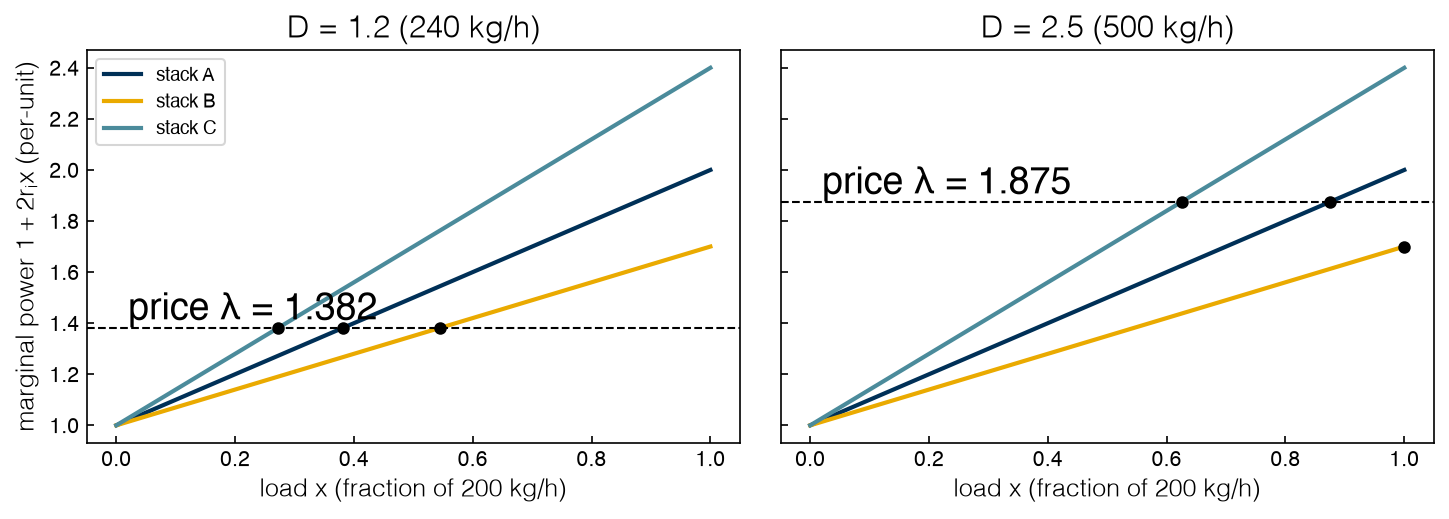

In [7]:
xx = np.linspace(0, 1, 100)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, D, lam, x in ((axes[0], 1.2, lam12, x12), (axes[1], 2.5, lam25, x25)):
    for c, xi in zip(el.NAMES, x):
        ax.plot(xx, 1 + 2 * el.R_OHMIC[c] * xx, label=f'stack {c}')
        ax.plot(xi, 1 + 2 * el.R_OHMIC[c] * xi, 'ko', ms=5)
    ax.axhline(lam, color='k', ls='--', lw=1)
    ax.text(0.02, lam + 0.03, f'price $\\lambda$ = {lam:.3f}')
    ax.set_title(f'D = {D} ({el.to_kg_h(D):.0f} kg/h)')
    ax.set_xlabel('load $x$ (fraction of 200 kg/h)')
axes[0].set_ylabel('marginal power $1 + 2 r_i x$ (per-unit)')
axes[0].legend(fontsize=9)
plt.tight_layout();

The figure shows the rule that each stack runs at the load where its marginal-power line crosses the price. On the right, the line for stack B ends at full load below the price, and the vertical gap at $x = 1$ is its capacity multiplier.

**Checking a candidate point.** The KKT conditions are also a test: given any proposed dispatch, we can ask whether it could be optimal. Stationarity fixes the multipliers. Every stack strictly between its bounds must have marginal power equal to $\lambda$; a full stack needs $\mu_i = \lambda - (1 + 2r_i) \ge 0$; an idle stack needs $\nu_i = 1 - \lambda \ge 0$. We test three candidates at $D = 1.2$.

In [8]:
rv = np.array([el.R_OHMIC[c] for c in el.NAMES])

def kkt_check(x, D, tol=1e-6):
    x = np.asarray(x, float); mc = 1 + 2 * rv * x                 # marginal powers
    issues = []
    if abs(x.sum() - D) > tol or np.any(x < -tol) or np.any(x > 1 + tol):
        return "not feasible"
    inner = (x > tol) & (x < 1 - tol)
    if inner.any() and np.ptp(mc[inner]) > tol:
        return f"not stationary: interior marginal powers {np.round(mc[inner], 3)} differ"
    lam = mc[inner].mean() if inner.any() else np.nan
    for i, c in enumerate(el.NAMES):
        if x[i] >= 1 - tol and lam - mc[i] < -tol:
            issues.append(f"mu_{c} = {lam - mc[i]:.2f} < 0")
        if x[i] <= tol and mc[i] - lam < -tol:
            issues.append(f"nu_{c} = {mc[i] - lam:.2f} < 0")
    return f"lambda = {lam:.5f}; " + ("KKT point" if not issues else "dual infeasible: " + ", ".join(issues))

for cand in [(0.4, 0.4, 0.4), (1.0, 0.2, 0.0), tuple(x12)]:
    print(f"x = {np.round(cand, 4)}: {kkt_check(cand, 1.2)}")

x = [0.4 0.4 0.4]: not stationary: interior marginal powers [1.4  1.28 1.56] differ
x = [1.  0.2 0. ]: lambda = 1.14000; dual infeasible: mu_A = -0.86 < 0, nu_C = -0.14 < 0
x = [0.3818 0.5455 0.2727]: lambda = 1.38182; KKT point


The equal split is feasible but not stationary: its marginal powers differ, so moving load from C to B lowers the total. The merit-order dispatch of the linear model, (1, 0.2, 0), is stationary for the only interior stack, B, with $\lambda = 1.14$, but both bounds have multipliers of the wrong sign: A's capacity multiplier would be $-0.86$ and C's would be $-0.14$. Negative multipliers say that the bounds are pulling rather than pushing, so moving off them improves the objective. Only the KKT dispatch passes, and because the problem is convex, passing the test proves global optimality.

**The thermodynamic reading.** Equal marginal power across running stacks is the same kind of condition as equal chemical potential across phases at equilibrium: no transfer of load from one stack to another can lower the total, just as no transfer of a species between phases can lower the Gibbs energy. The demand multiplier is the marginal energy to make one more unit of hydrogen with the fleet: 1.38182 per-unit is 328 kJ per mole of H₂, equivalent to a cell voltage of 1.70 V, or 45.2 kWh per kg. The ideal is 237 kJ/mol (1.229 V); the difference is dissipated as ohmic heat in the stacks, an irreversible loss.

**The economic reading.** A dispatcher running several plants equalizes their marginal costs, which is the textbook rule for **economic dispatch** of power plants. The demand multiplier is the price of hydrogen, that is, what one more kilogram costs the plant at the margin. In the linear dispatch the price jumped from one stack's cost to the next, but now it rises smoothly with demand, from 1.38182 at 240 kg/h to 1.875 at 500 kg/h. The capacity multiplier $\mu_B = 0.175$ is a **capacity rent**: one more unit of capacity on stack B would save 0.175 per-unit of power per unit of extra capacity, which is the most an operator should pay to uprate it.

:::{exercise}
:label: ex-t22-capacity-rent

Verify the capacity rent by finite differences: change stack B's capacity from 1 to $1 \pm 10^{-4}$ at $D = 2.5$ (pass `cap` as an array to a copy of `t2.ohmic_dispatch`, or edit the Pyomo model) and compute the change in total power. Then find the demand at which stack B first reaches capacity, and the demand at which a second stack does.
:::

## Summary

- The Lagrange function $\mathcal{L} = f - \sum_j \lambda_j(h_j - b_j)$ turns an equality-constrained problem into a stationarity problem. With this sign convention, $\lambda_j = \partial f^*/\partial b_j$ (the envelope theorem).
- A multiplier is the ratio of parallel gradients at a tangency, the force a constraint exerts, and the marginal value of relaxing the constraint.
- For the electrolysis cell, stationarity gives $\lambda_e = -FU$, $\mu_{\mathrm{H_2}} = 2\lambda_{\mathrm{H}} + 2FU$, $\mu_{\mathrm{O_2}} = 2\lambda_{\mathrm{O}}$ and $\mu_{\mathrm{H_2O}} = 2\lambda_{\mathrm{H}} + \lambda_{\mathrm{O}}$; eliminating the multipliers gives the Nernst equation. Ipopt's duals and finite differences agree.
- The KKT conditions add dual feasibility ($\nu \ge 0$) and complementary slackness ($\nu g = 0$). For convex problems with a strictly feasible point they are necessary and sufficient for a global minimum.
- Nonnegativity is the hidden inequality of Gibbs minimization. A species at zero has a nonnegative multiplier: it is priced out, by $2F(E^0 - U)$ for hydrogen in the LP limit below $E^0$.
- In the ohmic dispatch, KKT gives equal marginal power across running stacks. At $D = 1.2$, $\lambda = 1.38182$ (328 kJ/mol H₂, 45.2 kWh/kg) and $x = (0.3818, 0.5455, 0.2727)$; at $D = 2.5$ stack B is full, $\lambda = 1.875$, and B's capacity multiplier is 0.175.

## Additional Reading

- L. T. Biegler, *Nonlinear Programming: Concepts, Algorithms, and Applications to Chemical Processes*, SIAM (2010), Chapter 4, on KKT conditions and constraint qualifications.
- J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer (2006), Chapter 12, on the theory of constrained optimization.
- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006), Chapter 5, on constrained optimality criteria.
- W. R. Smith and R. W. Missen, *Chemical Reaction Equilibrium Analysis: Theory and Algorithms*, Wiley (1982), on Gibbs minimization with element balances and the meaning of the multipliers.
- D. Bertsimas and J. N. Tsitsiklis, *Introduction to Linear Optimization*, Athena Scientific (1997), Chapter 4, on dual variables as prices.